# Modelo VAEP Atômico Enriquecido com Features de Tracking

Este notebook implementa e avalia um modelo de valoração de ações no futebol (VAEP - Valuing Actions by Estimating Probabilities) com uma abordagem híbrida, combinando dados de evento (SPADL) com features extraídas de dados de tracking.

## Fluxo de Trabalho Experimental

O processo é dividido em **três grandes etapas** para permitir uma comparação justa e clara do impacto das features de tracking:

### 1. Modelo VAEP Baseline
- **Objetivo:** Estabelecer uma linha de base de performance.
- **Metodologia:** Um modelo VAEP atômico padrão é treinado utilizando exclusivamente features derivadas dos dados de evento SPADL. Este modelo serve como nosso ponto de referência.

### 2. Classificador de Sucesso Enriquecido
- **Objetivo:** Prever a probabilidade de uma ação ser bem-sucedida, utilizando um contexto tático que não está presente nos dados de evento.
- **Metodologia:**
    - Extraímos a feature **`compactação defensiva`** dos dados de tracking para cada ação.
    - Um classificador (XGBoost) é treinado para prever o sucesso de uma ação (`result_name`). As suas features de entrada são as features SPADL padrão **MAIS** a feature de `compactação defensiva`.
    - A performance deste classificador é avaliada para garantir que ele aprendeu padrões significativos.

### 3. Modelo VAEP Final (Híbrido)
- **Objetivo:** Avaliar o impacto de um classificador de sucesso "mais inteligente" na performance final do VAEP.
- **Metodologia:**
    - O classificador treinado na Etapa 2 é usado para gerar uma nova feature: `success_score` (a probabilidade de sucesso da ação).
    - Um novo modelo VAEP é treinado. Suas features de entrada são as features SPADL padrão **MAIS** a feature `success_score`.
    - A performance deste modelo final é comparada com o VAEP Baseline para quantificar o ganho obtido ao incorporar o contexto dos dados de tracking de forma indireta (através do classificador).

Ao final, o notebook gera os valores de VAEP para os jogadores e plota gráficos de diagnóstico detalhados para os modelos finais.

In [92]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.metrics import brier_score_loss
from socceraction.atomic.spadl import convert_to_atomic
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, roc_auc_score
import seaborn as sns
import os

In [93]:
import warnings
warnings.filterwarnings('ignore')

---

## Carregando dados de Evento e Transformação para Atomic SPADL

In [94]:
df_spadl = pd.read_parquet('spadl_events/spadl_ltr2.parquet')
df_spadl.head()

df_spadl['start_x'] = df_spadl['start_x'] * 105.0
df_spadl['start_y'] = df_spadl['start_y'] * 68.0
df_spadl['end_x'] = df_spadl['end_x'] * 105.0
df_spadl['end_y'] = df_spadl['end_y'] * 68.0

In [95]:
## Mantendo apenas a primeira linha de cada event_id

df_spadl = df_spadl.sort_values(by='time_seconds').drop_duplicates(subset=['original_event_id'], keep = 'first')

df_spadl['result_name'] = df_spadl['result_id'].map({
    1: 'success',
    0: 'fail'
})

In [96]:
# Ordenar ações por tempo dentro de cada jogo
df_spadl = df_spadl.sort_values(by=['game_id', 'period_id', 'time_seconds', 'action_id']).reset_index(drop=True)

In [97]:
df_spadl.shape

(299683, 17)

## Conversão de SPADL para Atomic SPADL

In [98]:
df_atomic = convert_to_atomic(df_spadl)
df_atomic = df_atomic[df_atomic['original_event_id'].notna()]
df_atomic.head()


,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id
0,13335,12926009.0,0,1,153.887,5.0,15620,52.826,34.309,-18.499,-4.643,0,5
1,13335,12926009.0,1,1,155.255,5.0,4696,34.327,29.666,0.000,0.000,23,0
2,13335,12926647.0,2,1,156.623,5.0,4696,34.623,31.107,45.198,18.914,0,5
3,13335,12926642.0,3,1,159.860,5.0,14278,79.821,50.021,NaN,NaN,9,0
4,13335,20246849.0,4,1,159.893,11.0,284,25.179,17.979,18.809,-10.268,18,0


In [99]:
df_atomic.sort_values(by=['x'])

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id
408633,13542,27296881.0,408633,1,810.4770,17.0,8074,0.0,66.390,0.0,0.0,10,0
396026,13537,16649597.0,396026,1,1762.3790,119.0,5063,0.0,67.586,0.0,0.0,10,0
396030,13537,16649702.0,396030,1,1814.5145,119.0,5063,0.0,67.807,0.0,0.0,10,0
120573,13425,15279359.0,120573,2,5765.0650,15.0,521,0.0,51.585,0.0,0.0,10,0
424745,13549,17058751.0,424745,1,2171.5380,17.0,12785,0.0,34.677,NaN,NaN,14,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
600990,13621,18803142.0,600990,2,5545.5460,218.0,7269,NaN,NaN,NaN,NaN,27,4
601071,13621,18803498.0,601071,2,5791.4750,218.0,7328,NaN,NaN,NaN,NaN,10,0
601073,13621,18803512.0,601073,2,5825.2420,218.0,7328,NaN,NaN,NaN,NaN,23,0
601075,13621,35050274.0,601075,2,5844.2440,218.0,7658,NaN,NaN,NaN,NaN,9,0


Adicionar a coluna `type_name` ao Atomic SPADL:

In [100]:
from socceraction.atomic.spadl.config import actiontypes as atomic_actiontypes

# Garante que o df_atomic.type_id só tenha valores válidos
max_atomic_id = len(atomic_actiontypes) - 1

df_atomic['type_name'] = df_atomic['type_id'].apply(
    lambda x: atomic_actiontypes[x] if 0 <= x <= max_atomic_id
              else f"unknown_{x}"
)

---

## Preparar dados para o Classificador de Sucesso

Carrega as features de tracking e prepara os dados para o classificador de sucesso:

In [101]:
print("Iniciando a integração das features de tracking...")
pasta_features_compaction = 'tracking_features/compaction/parquets_compaction'
lista_dfs_features = []
arquivos_features = [f for f in os.listdir(pasta_features_compaction) if f.endswith('.parquet')]

for nome_arquivo in tqdm(arquivos_features, desc="Carregando features de compactação"):
    caminho = os.path.join(pasta_features_compaction, nome_arquivo)
    lista_dfs_features.append(pd.read_parquet(caminho))

df_compaction_total = pd.concat(lista_dfs_features, ignore_index=True)
df_compaction_total.rename(columns={'possession_id': 'original_event_id'}, inplace=True)

# Garante que os tipos das chaves de merge são os mesmos para um merge seguro
df_compaction_total['original_event_id'] = df_compaction_total['original_event_id'].astype(float).astype(int).astype(str)
df_compaction_total['game_id'] = df_compaction_total['game_id'].astype(int)

print("\nFeatures de tracking carregadas e prontas.")
display(df_compaction_total.head())

Iniciando a integração das features de tracking...


Carregando features de compactação: 100%|██████████| 233/233 [00:00<00:00, 322.65it/s]



Features de tracking carregadas e prontas.


,original_event_id,defensive_compaction_x,defensive_compaction_y,game_id
0,12926009,11.509149,14.339360,13335
1,12926010,10.685111,11.034581,13335
2,12926642,17.266214,10.825132,13335
3,12926643,17.266214,10.825132,13335
4,12926647,13.028324,14.413517,13335


Adiciona coluna `result_name` ao Atomic SPADL:


In [102]:
df_atomic['original_event_id'] = df_atomic['original_event_id'].astype(str)
events_results = df_spadl.sort_values(by='time_seconds')[['original_event_id', 'result_name']].drop_duplicates(subset=['original_event_id'])
events_results['original_event_id'] = events_results['original_event_id'].astype(str)
df_atomic = df_atomic.merge(events_results, on='original_event_id', how='left')

df_atomic.head()

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id,type_name,result_name
0,13335,12926009.0,0,1,153.887,5.0,15620,52.826,34.309,-18.499,-4.643,0,5,pass,success
1,13335,12926009.0,1,1,155.255,5.0,4696,34.327,29.666,0.000,0.000,23,0,receival,success
2,13335,12926647.0,2,1,156.623,5.0,4696,34.623,31.107,45.198,18.914,0,5,pass,fail
3,13335,12926642.0,3,1,159.860,5.0,14278,79.821,50.021,NaN,NaN,9,0,tackle,fail
4,13335,20246849.0,4,1,159.893,11.0,284,25.179,17.979,18.809,-10.268,18,0,clearance,success


---

# Features e Labels para o Classificador de Sucesso

In [103]:
import socceraction.atomic.spadl as atomicspadl
import socceraction.atomic.vaep.features as fs
import socceraction.atomic.vaep.labels as lab
import socceraction.atomic.vaep.formula as fm

### Features

In [104]:
# ==========================
# 2. FEATURES ATOMIC
# ==========================

xfns = [
    fs.actiontype_onehot, fs.bodypart_onehot,
    fs.goalscore, fs.location, fs.polar,
    fs.direction, fs.team, fs.time, fs.time_delta,
]
nb_prev_actions = 3
Xcols = fs.feature_column_names(xfns, nb_prev_actions)

X_parts = []
for gid in tqdm(df_atomic.game_id.unique(), desc="Features"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    states = fs.gamestates(acts, nb_prev_actions)
    X_parts.append(pd.concat([fn(states) for fn in xfns], axis=1)[Xcols])
features = pd.concat(X_parts).reset_index(drop=True).fillna(0)


Features: 100%|██████████| 232/232 [00:13<00:00, 17.82it/s]


### Labels

In [105]:
import socceraction.atomic.vaep.labels as lab

Ycols = ["scores","concedes","result_name"]
Y_parts = []

for gid in tqdm(df_atomic.game_id.unique(), desc="Labels"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    Y_parts.append(pd.concat([lab.scores(acts), lab.concedes(acts), acts['result_name']], axis=1)[Ycols])
labels = pd.concat(Y_parts).reset_index(drop=True)

Labels:   0%|          | 0/232 [00:00<?, ?it/s]

Labels: 100%|██████████| 232/232 [00:08<00:00, 26.76it/s]


In [106]:
# Garante que features e labels têm o mesmo índice sequencial do df_atomic
features = features.reset_index(drop=True)
labels   = labels.reset_index(drop=True)

# Checagem de sanidade: todos os comprimentos batem?
assert len(features) == len(labels) == len(df_atomic), (
    f"Desalinhamento de índices: "
    f"df_atomic={len(df_atomic)}, features={len(features)}, labels={len(labels)}"
)


In [107]:
mask_goal = features['actiontype_goal_a0'] == True

# Remover as linhas que contêm gols
features = features[~mask_goal]
labels = labels[~mask_goal]
features.shape, labels.shape

((520061, 142), (520061, 3))

In [108]:
labels['result_name'] = labels['result_name'].replace({'success': 1, 'fail': 0})

In [109]:
# remove também as linhas que contêm gols de df_atomic
print(f"Antes de remover gols: {df_atomic.shape}")
df_atomic = df_atomic[df_atomic.type_name != 'goal'].reset_index(drop=True)
print(f"Depois de remover gols: {df_atomic.shape}")

Antes de remover gols: (520884, 15)
Depois de remover gols: (520061, 15)


In [110]:
# Célula de Verificação: Taxa de Sucesso Real dos Chutes
df_chutes = df_atomic[df_atomic['type_name'] == 'shot']
taxa_de_sucesso_real = df_chutes['result_name'].value_counts(normalize=True)

print("Taxa de sucesso real para ações do tipo 'shot':")
print(taxa_de_sucesso_real)

Taxa de sucesso real para ações do tipo 'shot':
result_name
fail       0.874236
success    0.125764
Name: proportion, dtype: float64


In [111]:
# teste rápido de alinhamento
assert len(df_atomic) == features.shape[0] == labels.shape[0], "Indices desalinhados!"

---

## Divisão Treino/Teste

In [112]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(
    gss.split(df_atomic, groups=df_atomic.game_id)
)

mask_train = df_atomic.index.isin(train_idx)
mask_test  = df_atomic.index.isin(test_idx)


# Separar as características (X) e os rótulos (y) com base nas máscaras
X_train = features[mask_train].reset_index(drop=True)
X_test  = features[mask_test].reset_index(drop=True)

y_train = labels[mask_train].reset_index(drop=True)
y_test  = labels[mask_test].reset_index(drop=True)

---

# Classificador - Score de Sucesso

### Enriquecimento - Features de Tracking
Enriquecimento com a feature de compactação defensiva dos dados de tracking.

In [115]:
print("Enriquecendo conjuntos de dados para o classificador...")

# Garante que os tipos das chaves em df_atomic são os corretos para o merge
df_atomic['original_event_id'] = df_atomic['original_event_id'].astype(float).astype(int).astype(str)
df_atomic['game_id'] = df_atomic['game_id'].astype(int)

# Função auxiliar para enriquecer um conjunto de dados X
def enrich_features(X_original, mask):
    keys = df_atomic[mask][['game_id', 'original_event_id']].reset_index(drop=True)
    merged_features = pd.merge(keys, df_compaction_total, on=['game_id', 'original_event_id'], how='left').fillna(0)
    X_enriched = pd.concat([
        X_original.reset_index(drop=True),
        merged_features[['defensive_compaction_x', 'defensive_compaction_y']]
    ], axis=1)
    return X_enriched

X_train_enriquecido = enrich_features(X_train, mask_train)
X_test_enriquecido = enrich_features(X_test, mask_test)

print("Conjuntos de dados enriquecidos criados: X_train_enriquecido, X_test_enriquecido.")
display(X_train_enriquecido.head())

Enriquecendo conjuntos de dados para o classificador...
Conjuntos de dados enriquecidos criados: X_train_enriquecido, X_test_enriquecido.


,actiontype_pass_a0,actiontype_cross_a0,actiontype_throw_in_a0,actiontype_freekick_crossed_a0,actiontype_freekick_short_a0,actiontype_corner_crossed_a0,actiontype_corner_short_a0,actiontype_take_on_a0,actiontype_foul_a0,actiontype_tackle_a0,...,period_id_a1,time_seconds_a1,time_seconds_overall_a1,period_id_a2,time_seconds_a2,time_seconds_overall_a2,time_delta_1,time_delta_2,defensive_compaction_x,defensive_compaction_y
0,True,False,False,False,False,False,False,False,False,False,...,1.0,153.887,153.887,1.0,153.887,153.887,0.000,0.000,11.509149,14.339360
1,False,False,False,False,False,False,False,False,False,False,...,1.0,153.887,153.887,1.0,153.887,153.887,1.368,1.368,11.509149,14.339360
2,True,False,False,False,False,False,False,False,False,False,...,1.0,155.255,155.255,1.0,153.887,153.887,1.368,2.736,13.028324,14.413517
3,False,False,False,False,False,False,False,False,False,True,...,1.0,156.623,156.623,1.0,155.255,155.255,3.237,4.605,17.266214,10.825132
4,False,False,False,False,False,False,False,False,False,False,...,1.0,159.860,159.860,1.0,156.623,156.623,0.033,3.270,0.000000,0.000000


### Avaliar quais os melhores parâmetros para o classificador

In [116]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

# Não executar a busca de hiperparâmetros se não for necessário
if False:
    scale_pos_weight = (1 / y_train['result_name'].mean() - 1)

    param_dist = {
        'n_estimators': [50, 5000, 1000, 2000],
        'max_depth': [3,5,7],
        'learning_rate': [0.01,0.03,0.05],
        'subsample': [0.6,0.8,1.0],
        'colsample_bytree': [0.6,0.8,1.0],
        'reg_alpha': [0,0.5,1],
        'reg_lambda': [0,0.5,1],
        'scale_pos_weight': [scale_pos_weight*0.5, scale_pos_weight, scale_pos_weight*2]
    }

    cv = GroupKFold(n_splits=4)
    search = RandomizedSearchCV(
        XGBClassifier(objective='binary:logistic', use_label_encoder=False, eval_metric='auc'),
        param_dist,
        n_iter=20,
        scoring='roc_auc',
        cv=cv.split(X_train_enriquecido, y_train['result_name'], groups=df_atomic['game_id'][mask_train]),
        random_state=42,
        verbose=2,
        n_jobs=-1
    )

    search.fit(X_train_enriquecido, y_train['result_name'])
    print("Best params:", search.best_params_)
    classificador_sucesso = search.best_estimator_


### Treino - Classificador

In [117]:
from sklearn.metrics import brier_score_loss, roc_auc_score, log_loss

def evaluate(y, y_hat, label=""):
    p = y.mean()
    base = np.full_like(y, p, dtype=float)
    brier = brier_score_loss(y, y_hat)
    base_brier = brier_score_loss(y, base)
    ll = log_loss(y, y_hat)
    base_ll = log_loss(y, base)

    print(f"### {label.upper()} ###")
    print(f"  Brier score : {brier:.5f} ({brier / base_brier:.5f})")
    print(f"  Log loss    : {ll:.5f} ({ll / base_ll:.5f})")
    print(f"  ROC AUC     : {roc_auc_score(y, y_hat):.5f}\n")

In [118]:

from sklearn.calibration import CalibratedClassifierCV

print("\n### TREINANDO CLASSIFICADOR DE SUCESSO ###")

scale_pos_weight = (1 / y_train['result_name'].mean() - 1)
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

classificador_sucesso = XGBClassifier(
    n_estimators=5000, max_depth=7, learning_rate=0.01, subsample=0.8, colsample_bytree=0.6,
    scale_pos_weight= scale_pos_weight,
    enable_categorical=True, use_label_encoder=False, eval_metric='logloss',
    random_state=42, n_jobs=-1, reg_alpha=0.5, reg_lambda=0.5, early_stopping_rounds=50
)

Xcs_tr, Xcs_val, ycs_tr, ycs_val = train_test_split(
    X_train_enriquecido, 
    y_train['result_name'],
    test_size=0.1, 
    stratify=y_train['result_name'], 
    random_state=42
)

classificador_sucesso.fit(
    Xcs_tr, ycs_tr,
    eval_set=[(Xcs_val, ycs_val)],
)


### TREINANDO CLASSIFICADOR DE SUCESSO ###
scale_pos_weight: 0.27
[0]	validation_0-logloss:0.68846
[1]	validation_0-logloss:0.68312
[2]	validation_0-logloss:0.67869
[3]	validation_0-logloss:0.67481
[4]	validation_0-logloss:0.67056
[5]	validation_0-logloss:0.66524
[6]	validation_0-logloss:0.66022
[7]	validation_0-logloss:0.65595
[8]	validation_0-logloss:0.65121
[9]	validation_0-logloss:0.64719
[10]	validation_0-logloss:0.64232
[11]	validation_0-logloss:0.63851
[12]	validation_0-logloss:0.63433
[13]	validation_0-logloss:0.63042
[14]	validation_0-logloss:0.62650
[15]	validation_0-logloss:0.62284
[16]	validation_0-logloss:0.62025
[17]	validation_0-logloss:0.61643
[18]	validation_0-logloss:0.61319
[19]	validation_0-logloss:0.60993
[20]	validation_0-logloss:0.60647
[21]	validation_0-logloss:0.60292
[22]	validation_0-logloss:0.59998
[23]	validation_0-logloss:0.59607
[24]	validation_0-logloss:0.59293
[25]	validation_0-logloss:0.59010
[26]	validation_0-logloss:0.58659
[27]	validation_0-logloss

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device=None, early_stopping_rounds=50,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.01, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=5000, n_jobs=-1,
              num_parallel_tree=None, ...)

In [124]:
calib = CalibratedClassifierCV(
    estimator=classificador_sucesso,
    method='sigmoid', cv="prefit"
)

calib.fit(Xcs_val, ycs_val)

# Avaliação do classificador
# <<< ALTERAÇÃO 3: predições em validação e teste externo >>>
# yhat_val = classificador_sucesso.predict_proba(Xcs_val)[:, 1]         # nova variável
yhat_val = calib.predict_proba(Xcs_val)[:, 1]  # modificado
# yhat_test = classificador_sucesso.predict_proba(X_test_enriquecido)[:, 1]  # modificado
yhat_test = calib.predict_proba(X_test_enriquecido)[:, 1]  # modificado

print("\nAvaliando a performance do classificador de sucesso:")
evaluate(ycs_val,   yhat_val,  label="VAL SET (Treino do Classificador)")  # modificado
evaluate(y_test['result_name'], yhat_test, label="TEST SET (VAEP)        ")  # modificado


Avaliando a performance do classificador de sucesso:
### VAL SET (TREINO DO CLASSIFICADOR) ###
  Brier score : 0.06744 (0.40297)
  Log loss    : 0.22323 (0.43152)
  ROC AUC     : 0.95695

### TEST SET (VAEP)         ###
  Brier score : 0.06619 (0.41189)
  Log loss    : 0.21856 (0.43538)
  ROC AUC     : 0.95644



### Curva de Calibração do Classificador

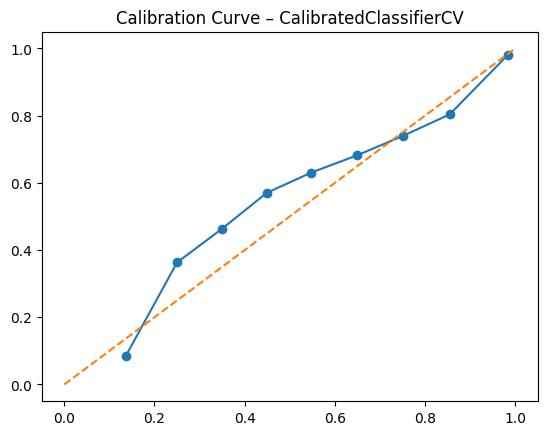

In [125]:
from sklearn.calibration import calibration_curve
prob_true, prob_pred = calibration_curve(y_test['result_name'], yhat_test, n_bins=10)

import matplotlib.pyplot as plt
plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0,1],[0,1],"--")
plt.title("Calibration Curve – CalibratedClassifierCV")
plt.show()

---

## Atomic VAEP + Classificador_sucesso

In [144]:
## Scores
train_score = calib.predict_proba(X_train_enriquecido)[:, 1]
test_score = calib.predict_proba(X_test_enriquecido)[:, 1]
len(train_score)

413361

In [145]:
X_train['success_score'] = train_score
X_test['success_score'] = test_score

In [ ]:
X_train['vaep_relevant_success'] = X_train['success_score'] * X_train['dx_a0'] # Sucesso que avança em campo
X_train['vaep_goal_threat_success'] = X_train['success_score'] / (X_train['dist_to_goal_a0'] + 1e-6) # Sucesso perto do gol

# X_test['vaep_relevant_success'] = X_test['success_score'] * X_test['dx_a0'] # Sucesso que avança em campo
# X_test['vaep_goal_threat_success'] = X_test['success_score'] / (X_test['dist_to_goal_a0'] + 1e-6) # Sucesso perto do gol

# X_train['shot_value'] = X_train['success_score'] * X_train['actiontype_shot_a0']
# X_test['shot_value'] = X_test['success_score'] * X_test['actiontype_shot_a0']

# X_train['speed_of_play_value'] = X_train['success_score'] / (X_train['time_delta_1'] + 0.1)
# X_test['speed_of_play_value'] = X_test['success_score'] / (X_test['time_delta_1'] + 0.1)

# remover feature sucess_score
X_train.drop(columns=['success_score'], inplace=True)
X_test.drop(columns=['success_score'], inplace=True)


In [147]:
print("\n### TREINANDO MODELO VAEP FINAL (com success_score) ###")
final_vaep_models = {}
for target in ['scores', 'concedes']:
    clf = XGBClassifier(
        n_estimators=800,
        max_depth=7,
        enable_categorical=True,
        n_jobs=-3,
        reg_lambda=1.0,
        subsample=0.6,
        learning_rate=0.01,
        colsample_bytree=0.6,
        random_state=42
    )
    clf.fit(X_train, y_train[target])
    final_vaep_models[target] = clf
    
    yhat_train = clf.predict_proba(X_train)[:, 1]
    yhat_test = clf.predict_proba(X_test)[:, 1]
    evaluate(y_train[target], yhat_train, label=f"FINAL VAEP {target} - TRAIN")
    evaluate(y_test[target], yhat_test, label=f"FINAL VAEP {target} - TEST")


### TREINANDO MODELO VAEP FINAL (com success_score) ###
### FINAL VAEP SCORES - TRAIN ###
  Brier score : 0.00999 (0.82610)
  Log loss    : 0.04512 (0.68297)
  ROC AUC     : 0.91974

### FINAL VAEP SCORES - TEST ###
  Brier score : 0.00999 (0.94900)
  Log loss    : 0.04983 (0.84594)
  ROC AUC     : 0.81279

### FINAL VAEP CONCEDES - TRAIN ###
  Brier score : 0.00206 (0.85540)
  Log loss    : 0.00966 (0.56982)
  ROC AUC     : 0.98539

### FINAL VAEP CONCEDES - TEST ###
  Brier score : 0.00175 (0.99118)
  Log loss    : 0.01159 (0.89190)
  ROC AUC     : 0.79990



---

## Feature Importance no VAEP


Top 10 features por ganho (total_gain):
                            total_gain
dist_to_goal_a0           65653.718750
vaep_relevant_success     32519.486328
vaep_goal_threat_success  28571.808594
x_a0                      26424.599609
actiontype_shot_a0        24077.931641
time_seconds_a0           16683.119141
time_delta_2              16286.450195
dx_a0                     16012.630859
dx_a1                     15566.403320
y_a0                      15386.369141

A coluna 'success_score' não apareceu entre as features usadas (verifique se ela está em X_train).


<Axes: title={'center': 'Top 10 Feature Importances (total_gain)'}>

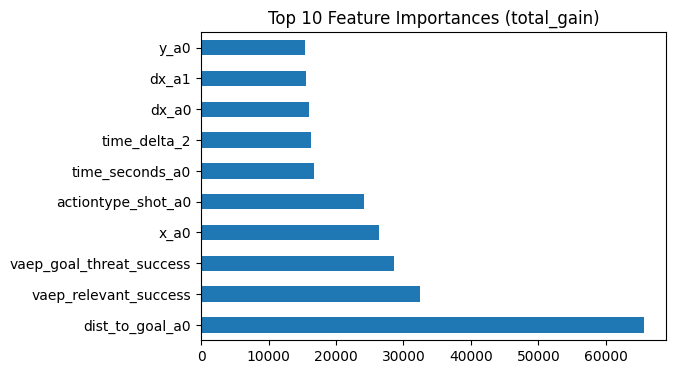

In [ ]:
# ─────────── AQUI ───────────
# Calcular feature importance da coluna success_score no modelo 'scores'
scores_model = final_vaep_models['scores']
booster = scores_model.get_booster()
imp_dict = booster.get_score(importance_type='total_gain')

import pandas as pd
imp_df = (
    pd.DataFrame.from_dict(imp_dict, orient='index', columns=['total_gain'])
      .sort_values('total_gain', ascending=False)
)
print("\nTop 10 features por ganho (total_gain):")
print(imp_df.head(10))

if 'success_score' in imp_df.index:
    print(f"\nImportância de success_score: {imp_df.loc['success_score','total_gain']:.4f}")
else:
    print("\nA coluna 'success_score' não apareceu entre as features usadas (verifique se ela está em X_train).")

# Se quiser visualizar graficamente:
imp_df.head(10).plot.barh(figsize=(6,4), legend=False, title="Top 10 Feature Importances (total_gain)")

---

## Predições - Jogadores

In [ ]:
# ==========================
# 6. PREDIÇÕES
# ==========================

def generate_predictions(features, models):
    if 'success_score' not in features.columns:
        features_enriquecido = enrich_features(features, features.index.isin(features.index)) # Enriquece todo o conjunto
        success_score_all = models['result_name'].predict_proba(features_enriquecido)[:, 1]
        features['success_score'] = success_score_all
        
    preds = {}
    for m in ['scores', 'concedes']:
        preds[m] = models[m].predict_proba(features)[:, 1]
    return pd.DataFrame(preds)

preds_my = generate_predictions(features, {'result_name': classificador_sucesso, **final_vaep_models})


In [ ]:
def calculate_action_values(spadl, predictions):
    values = fm.value(actions=spadl, Pscores=predictions['scores'], Pconcedes=predictions['concedes'])
    return pd.concat([
        spadl[['game_id', 'action_id', 'player_id', 'type_name']],
        predictions.rename(columns={'scores': 'Pscores', 'concedes': 'Pconcedes'}),
        values
    ], axis=1)

df_atomic_aligned = df_atomic.reset_index(drop=True)
preds_my_aligned = preds_my.reset_index(drop=True)
vaep_my = calculate_action_values(df_atomic_aligned, preds_my_aligned)


In [ ]:
print(vaep_my.sort_values('vaep_value', ascending=False).head())

vaep_by_player = vaep_my.groupby('player_id')['vaep_value'].sum().sort_values(ascending=False)
print("\nVAEP total por jogador:")
print(vaep_by_player.head())

        game_id  action_id  ... defensive_value vaep_value
139380    13444     161247  ...        0.918909   0.921639
422477    13573     488301  ...        0.905060   0.906558
302543    13518     349857  ...        0.904485   0.905505
209974    13476     242779  ...        0.899875   0.898139
178889    13462     206974  ...        0.891574   0.890987

[5 rows x 9 columns]

VAEP total por jogador:
player_id
4775     14.659341
1930     14.310700
12785    13.757553
133      13.715244
7328     13.397848
Name: vaep_value, dtype: float32


---

# Diagnóstico Visual dos Modelos Finais

In [ ]:
Y_hat_train_final = pd.DataFrame()
Y_hat_test_final = pd.DataFrame()

for target in ['scores', 'concedes']:
    # Usamos os modelos do 'final_vaep_models' para prever nos conjuntos de treino e teste
    # Note que X_train e X_test aqui são os que contêm a coluna 'success_score'
    Y_hat_train_final[target] = final_vaep_models[target].predict_proba(X_train)[:, 1]
    Y_hat_test_final[target] = final_vaep_models[target].predict_proba(X_test)[:, 1]

print("Predições dos modelos finais coletadas.")

Predições dos modelos finais coletadas.


In [ ]:
# %%
# --- ETAPA 9.2: Definição da Função de Plotagem ---
# (Esta é a sua função, copiada aqui para manter a célula autocontida)

def plot_model_diagnostics(y_train, y_test, yhat_train, yhat_test, label):
    """
    Plota curva de calibração, curva ROC e distribuição de probabilidades previstas.
    """
    plt.figure(figsize=(18, 5))

    # -------- Curva de Calibração --------
    plt.subplot(1, 3, 1)
    prob_true_train, prob_pred_train = calibration_curve(y_train, yhat_train, n_bins=10, strategy='uniform')
    prob_true_test, prob_pred_test = calibration_curve(y_test, yhat_test, n_bins=10, strategy='uniform')

    plt.plot(prob_pred_train, prob_true_train, marker='o', label='Treino')
    plt.plot(prob_pred_test, prob_true_test, marker='s', label='Teste')
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    plt.title(f'Curva de Calibração - {label}')
    plt.xlabel('Probabilidade Prevista')
    plt.ylabel('Frequência Real')
    plt.legend()
    plt.grid(True)

    # -------- Curva ROC --------
    plt.subplot(1, 3, 2)
    fpr_train, tpr_train, _ = roc_curve(y_train, yhat_train)
    fpr_test, tpr_test, _ = roc_curve(y_test, yhat_test)

    auc_train = roc_auc_score(y_train, yhat_train)
    auc_test = roc_auc_score(y_test, yhat_test)

    plt.plot(fpr_train, tpr_train, label=f'Treino (AUC={auc_train:.5f})')
    plt.plot(fpr_test, tpr_test, label=f'Teste (AUC={auc_test:.5f})')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(f'Curva ROC - {label}')
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.legend()
    plt.grid(True)

    # -------- Distribuição das Probabilidades Previstas --------
    plt.subplot(1, 3, 3)
    sns.kdeplot(yhat_train, label='Treino', fill=True)
    sns.kdeplot(yhat_test, label='Teste', fill=True)
    plt.title(f'Distribuição de Probabilidades - {label}')
    plt.xlabel('Probabilidade prevista')
    plt.ylabel('Densidade')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###



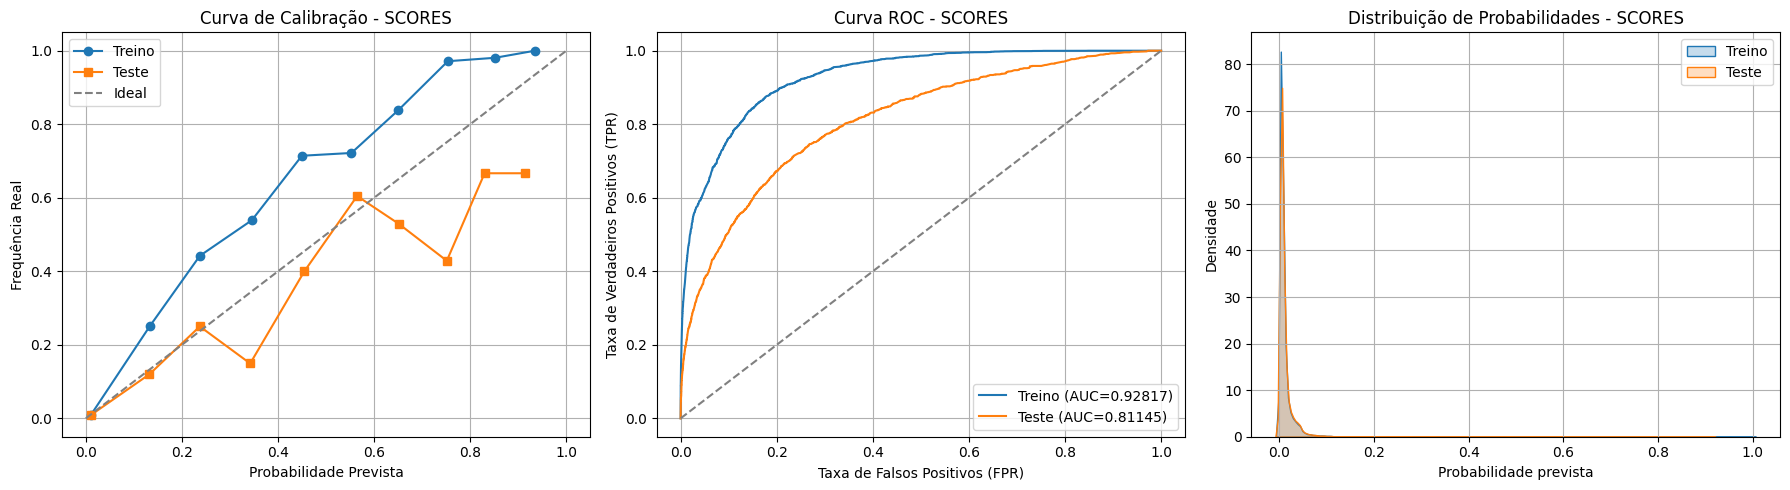

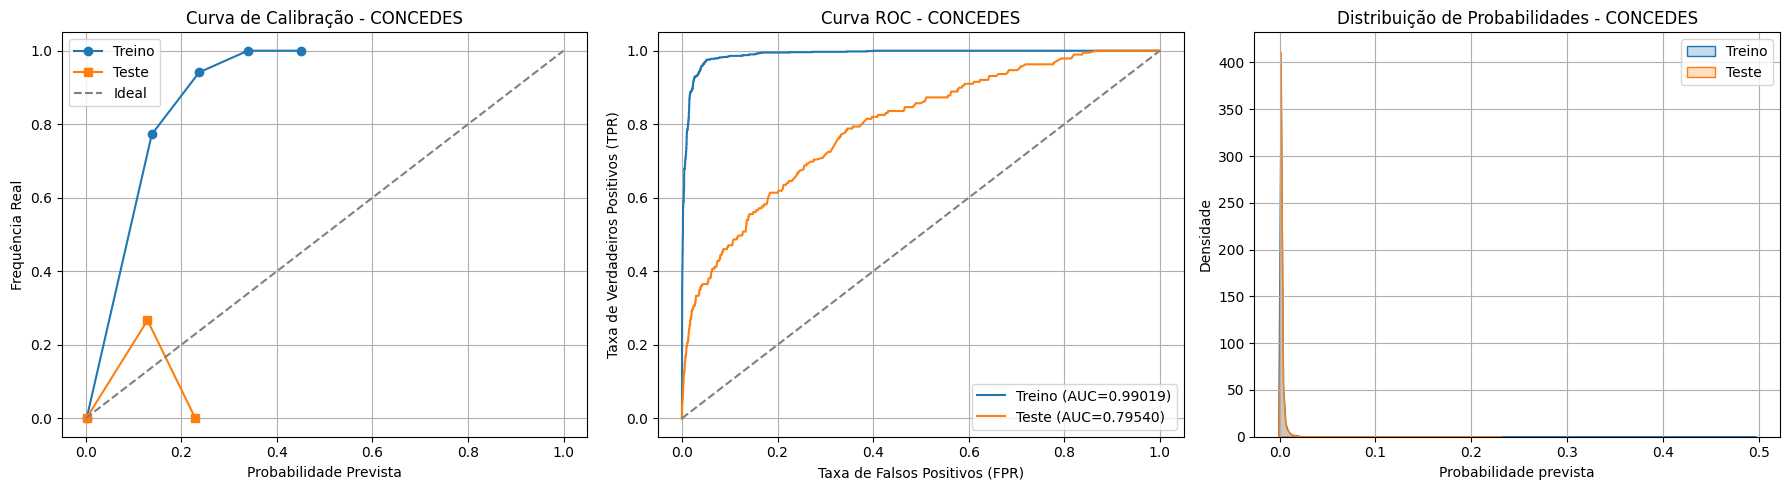

In [ ]:
print("\n### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###\n")

for col in ['scores', 'concedes']:
    plot_model_diagnostics(
        y_train[col], 
        y_test[col], 
        Y_hat_train_final[col], 
        Y_hat_test_final[col], 
        label=col.upper()
    )

In [ ]:
df_atomic

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id,type_name,result_name
0,13335,12926009,0,1,153.887,5.0,15620,52.826,34.309,-18.499,-4.643,0,5,pass,success
1,13335,12926009,1,1,155.255,5.0,4696,34.327,29.666,0.000,0.000,23,0,receival,success
2,13335,12926647,2,1,156.623,5.0,4696,34.623,31.107,45.198,18.914,0,5,pass,fail
3,13335,12926642,3,1,159.860,5.0,14278,79.821,50.021,NaN,NaN,9,0,tackle,fail
4,13335,20246849,4,1,159.893,11.0,284,25.179,17.979,18.809,-10.268,18,0,clearance,success
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520056,13621,18803885,601140,2,6067.134,218.0,102,65.365,58.755,NaN,NaN,9,0,tackle,success
520057,13621,18803906,601141,2,6095.830,218.0,102,75.750,54.667,20.560,-30.762,0,5,pass,fail
520058,13621,18803919,601142,2,6098.732,218.0,567,96.310,23.905,NaN,NaN,9,0,tackle,success
520059,13621,18803920,601143,2,6098.765,218.0,567,96.432,23.710,5.675,8.382,0,1,pass,fail


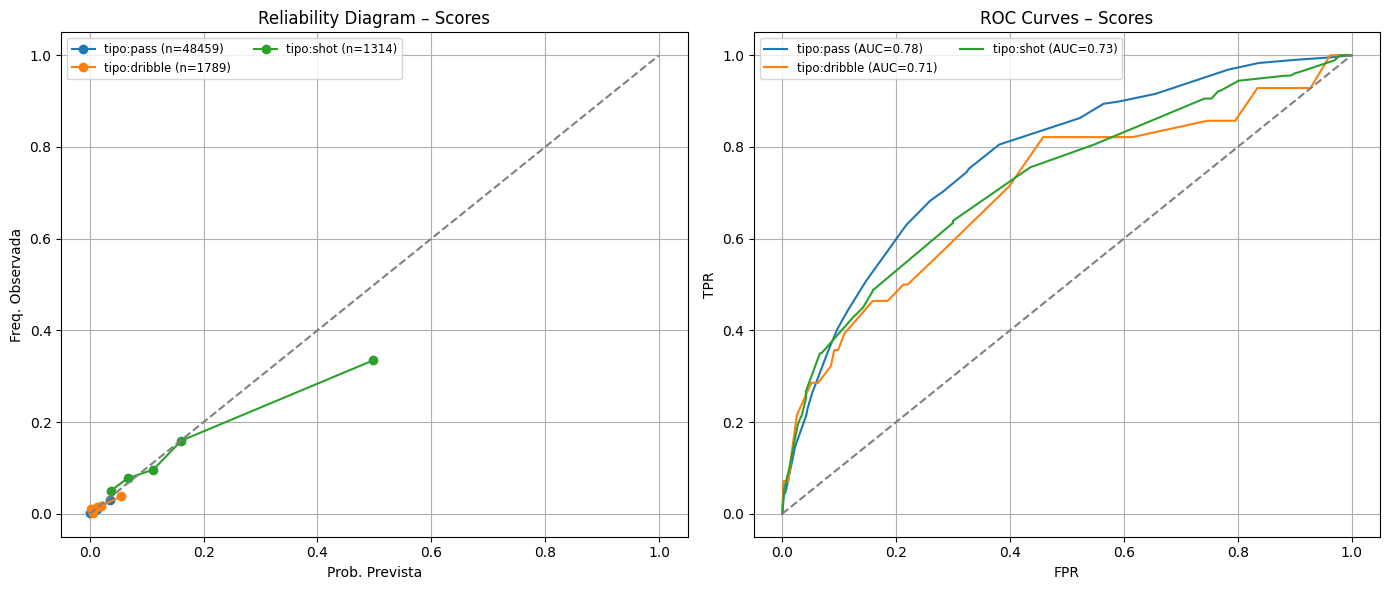

Segment     |   Brier    | Rel. Brier |  ROC AUC
------------|------------|------------|---------
tipo:pass  |   0.00842 |     0.008 |   0.775
tipo:dribble |   0.01504 |     0.015 |   0.706
tipo:shot  |   0.11048 |     0.128 |   0.726


In [ ]:
# %% [markdown]
# ## Avaliação Segmentada por Tipo de Ação e Zona do Campo

# %% 
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.calibration import calibration_curve

# 1) Defina seus segmentos de interesse
#    usamos df_atomic.reset_index() para alinhar com X_test e Y_hat_test_final
df_eval = df_atomic.reset_index(drop=True).loc[mask_test].copy()
df_eval['y_true']  = y_test['scores'].values
df_eval['y_pred']  = Y_hat_test_final['scores'].values

# 1a) Tipos de ação
action_types = ['pass', 'dribble', 'shot']


segments = {
    **{f"tipo:{a}": df_eval['type_name']==a for a in action_types}
}

# 2) Para cada segmento, calcule métrica e plote Curva de Calibração e ROC
plt.figure(figsize=(14, 6))

# 2a) Calibração por segmento
plt.subplot(1,2,1)
for name, mask in segments.items():
    y_true_seg = df_eval.loc[mask, 'y_true']
    y_pred_seg = df_eval.loc[mask, 'y_pred']
    if len(y_true_seg)==0: continue
    prob_true, prob_pred = calibration_curve(y_true_seg, y_pred_seg, n_bins=5, strategy='quantile')
    plt.plot(prob_pred, prob_true, marker='o', label=f"{name} (n={len(y_true_seg)})")
plt.plot([0,1],[0,1],'--', color='gray')
plt.title("Reliability Diagram – Scores")
plt.xlabel("Prob. Prevista")
plt.ylabel("Freq. Observada")
plt.legend(fontsize='small', ncol=2)
plt.grid(True)

# 2b) ROC por segmento
plt.subplot(1,2,2)
for name, mask in segments.items():
    y_true_seg = df_eval.loc[mask, 'y_true']
    y_pred_seg = df_eval.loc[mask, 'y_pred']
    if len(y_true_seg)==0: continue
    auc = roc_auc_score(y_true_seg, y_pred_seg)
    fpr, tpr, _ = roc_curve(y_true_seg, y_pred_seg)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})")
plt.plot([0,1],[0,1],'--', color='gray')
plt.title("ROC Curves – Scores")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend(fontsize='small', ncol=2)
plt.grid(True)

plt.tight_layout()
plt.show()

# 3) Métricas numéricas: Brier + AUC por segmento
print("Segment     |   Brier    | Rel. Brier |  ROC AUC")
print("------------|------------|------------|---------")
p = df_eval['y_true'].mean()
for name, mask in segments.items():
    y_true_seg = df_eval.loc[mask, 'y_true']
    y_pred_seg = df_eval.loc[mask, 'y_pred']
    if len(y_true_seg)==0: continue
    b   = brier_score_loss(y_true_seg, y_pred_seg)
    base= brier_score_loss(y_true_seg, np.full_like(y_true_seg, p))
    auc = roc_auc_score(y_true_seg, y_pred_seg)
    print(f"{name:10s} | {b:9.5f} | {b/base:9.3f} | {auc:7.3f}")
